# Phase 3 — Evaluation Protocol & Baselines

> **Protocol locked before model comparison**
>
> - **Forecast origin:** end of July. July's value is assumed known at July month-end (the Census publishes with a lag; if operational forecasts are issued earlier, move the origin back).
> - **Horizon:** the next 12 calendar months, **August through July**.
> - **Validation folds** (model selection): Jul 2016, 2017, 2018, 2019, 2022, 2023.
> - **Stress folds** (COVID, reported separately and unmasked, never used to select): Jul 2020, 2021.
> - **Test folds** (the most recent 24 months, Aug 2024 – Jul 2026): Jul 2024, 2025. **Locked in code:** only `evaluate(..., final=True)` can score them, once, at the very end.
> - **Training boundary:** every forecast function receives only the series through that fold's `train_end`.
> - **Scoring mask:** exclude target months **Mar 2020 – Jun 2021** from primary scoring.
> - **Success bar for models:** pooled RelMAE ≤ **0.90** versus seasonal naive **and** beat it in at least **4 of 6** validation folds.
> - **Drift estimators:** growth is computed only from YoY rows whose current and comparison months are unmasked. The trailing-12 estimator falls back to zero drift when fewer than 6 clean observations exist.
> - **December:** absolute percentage error; one December per fold is not enough to infer a calendar-placement effect.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.analysis.eda_helper import load_apparel_data
from src.evaluation import (
    VALIDATION_ORIGINS, STRESS_ORIGINS, TEST_ORIGINS, MASK_START, MASK_END, MIN_TRAILING_OBS,
    get_forecast_folds, seasonal_naive_forecast, make_drift_forecaster,
    trailing_growth, eligible_yoy_growth, evaluate,
)

y = load_apparel_data()["apparel_sales_nsa"].dropna().astype(float)
print(f"Dataset: {len(y):,} monthly observations, {y.index.min():%Y-%m} to {y.index.max():%Y-%m}\n")
for label, origins in [("VALIDATION", VALIDATION_ORIGINS), ("STRESS", STRESS_ORIGINS), ("TEST (locked)", TEST_ORIGINS)]:
    for fold in get_forecast_folds(origins, data_end=y.index.max()):
        m = fold["forecast_months"]
        print(f"{label:14s} origin {fold['origin']:%Y-%m} | train through {fold['train_end']:%Y-%m} | forecast {m[0]:%Y-%m} to {m[-1]:%Y-%m}")

Dataset: 415 monthly observations, 1992-01 to 2026-07

VALIDATION     origin 2016-07 | train through 2016-07 | forecast 2016-08 to 2017-07
VALIDATION     origin 2017-07 | train through 2017-07 | forecast 2017-08 to 2018-07
VALIDATION     origin 2018-07 | train through 2018-07 | forecast 2018-08 to 2019-07
VALIDATION     origin 2019-07 | train through 2019-07 | forecast 2019-08 to 2020-07
VALIDATION     origin 2022-07 | train through 2022-07 | forecast 2022-08 to 2023-07
VALIDATION     origin 2023-07 | train through 2023-07 | forecast 2023-08 to 2024-07
STRESS         origin 2020-07 | train through 2020-07 | forecast 2020-08 to 2021-07
STRESS         origin 2021-07 | train through 2021-07 | forecast 2021-08 to 2022-07
TEST (locked)  origin 2024-07 | train through 2024-07 | forecast 2024-08 to 2025-07
TEST (locked)  origin 2025-07 | train through 2025-07 | forecast 2025-08 to 2026-07


### Split diagram

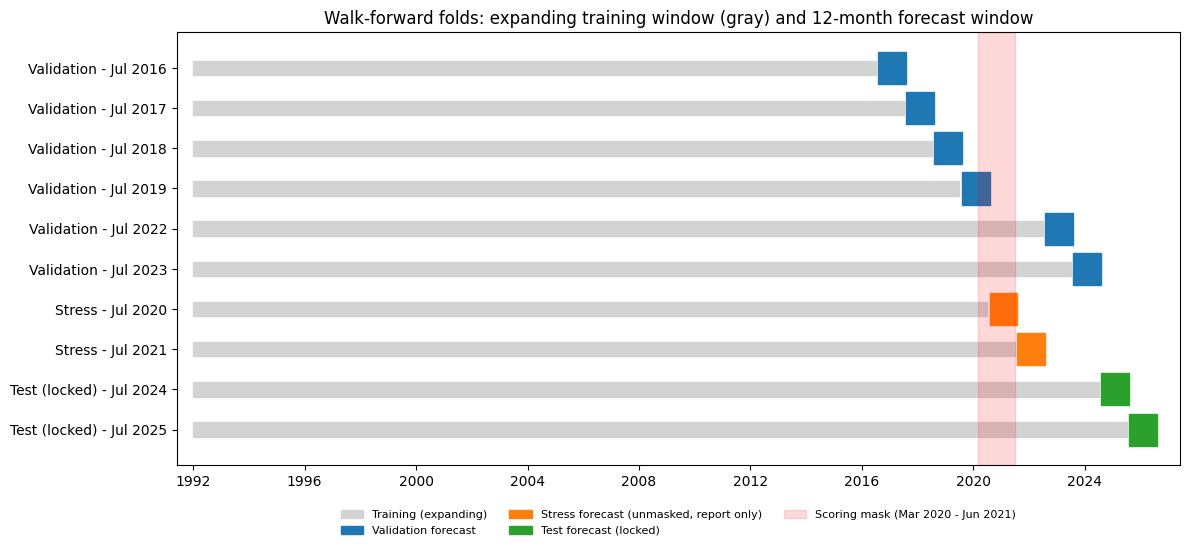

In [2]:
rows = ([("Validation", o, "tab:blue") for o in VALIDATION_ORIGINS]
        + [("Stress", o, "tab:orange") for o in STRESS_ORIGINS]
        + [("Test (locked)", o, "tab:green") for o in TEST_ORIGINS])

fig, ax = plt.subplots(figsize=(12, 5.6))
start_num = mdates.date2num(y.index.min())
for i, (group, origin, color) in enumerate(rows):
    fold = get_forecast_folds([origin], data_end=y.index.max())[0]
    train_end = mdates.date2num(fold["train_end"])
    f0 = mdates.date2num(fold["forecast_months"][0])
    f1 = mdates.date2num(fold["forecast_months"][-1] + pd.offsets.MonthEnd(0))
    ax.broken_barh([(start_num, train_end - start_num)], (i - 0.18, 0.36), color="lightgray")
    ax.broken_barh([(f0, f1 - f0)], (i - 0.4, 0.8), color=color)
ax.axvspan(mdates.date2num(MASK_START), mdates.date2num(MASK_END), color="red", alpha=0.15)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{g} - Jul {pd.Timestamp(o).year}" for g, o, _ in rows])
ax.invert_yaxis()
ax.xaxis_date()
ax.set_title("Walk-forward folds: expanding training window (gray) and 12-month forecast window")
ax.legend(handles=[Patch(color="lightgray", label="Training (expanding)"),
                   Patch(color="tab:blue", label="Validation forecast"),
                   Patch(color="tab:orange", label="Stress forecast (unmasked, report only)"),
                   Patch(color="tab:green", label="Test forecast (locked)"),
                   Patch(color="red", alpha=0.15, label="Scoring mask (Mar 2020 - Jun 2021)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8, frameon=False)
ax.set_xlim(mdates.date2num(pd.Timestamp("1991-06-01")), mdates.date2num(pd.Timestamp("2027-06-01")))
fig.tight_layout()
(project_root / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(project_root / "reports" / "figures" / "split_diagram.png", dpi=150)
plt.show()

### Drift selection on the six validation folds

In [3]:
candidate_forecasters = {
    "Seasonal Naive": seasonal_naive_forecast,
    "Drift: masked mean YoY": make_drift_forecaster("mean_all"),
    "Drift: masked median YoY": make_drift_forecaster("median_all"),
    "Drift: trailing-12-month mean YoY": make_drift_forecaster("mean_trailing12"),
}
# evaluate() defaults to VALIDATION_ORIGINS and refuses the locked test origins.
validation_tables = {name: evaluate(fn, y) for name, fn in candidate_forecasters.items()}

drift_names = [n for n in candidate_forecasters if n != "Seasonal Naive"]
pooled_scores = {n: validation_tables[n]["MAE"].sum() / validation_tables[n]["Benchmark_SN_MAE"].sum() for n in drift_names}
best_drift_name = min(pooled_scores, key=pooled_scores.get)
print("Pooled RelMAE vs seasonal naive (six validation folds):")
print(pd.Series(pooled_scores, name="Pooled RelMAE").sort_values().round(3))
print(f"\nSelected drift baseline: {best_drift_name}")

# How many clean YoY observations feed each drift estimate, per fold?
rate_rows = []
for fold in get_forecast_folds(VALIDATION_ORIGINS, data_end=y.index.max()):
    train = y.loc[:fold["train_end"]]
    growth = eligible_yoy_growth(train)
    t_rate, t_n = trailing_growth(train)
    rate_rows.append({"Origin": f"{fold['origin']:%Y-%m}", "All_history_mean_%": growth.mean() * 100,
                      "All_history_median_%": growth.median() * 100, "Trailing12_%": t_rate * 100,
                      "Trailing12_n_obs": t_n, "Zero_drift_fallback": t_n < MIN_TRAILING_OBS})
rate_df = pd.DataFrame(rate_rows)
display(rate_df.round(2))
print(f"Folds using the zero-drift fallback: {int(rate_df['Zero_drift_fallback'].sum())}")

Pooled RelMAE vs seasonal naive (six validation folds):
Drift: trailing-12-month mean YoY    0.930
Drift: masked mean YoY               1.060
Drift: masked median YoY             1.132
Name: Pooled RelMAE, dtype: float64

Selected drift baseline: Drift: trailing-12-month mean YoY


,Origin,All_history_mean_%,All_history_median_%,Trailing12_%,Trailing12_n_obs,Zero_drift_fallback
0,2016-07,3.47,3.86,1.33,12,False
1,2017-07,3.37,3.72,0.87,12,False
2,2018-07,3.29,3.61,1.35,12,False
3,2019-07,3.19,3.40,0.77,12,False
4,2022-07,3.16,3.38,-2.39,1,True
5,2023-07,3.07,3.31,0.82,12,False


Folds using the zero-drift fallback: 1


In [4]:
sn_results = validation_tables["Seasonal Naive"]
drift_results = validation_tables[best_drift_name]

results_df = sn_results[["Origin", "Train_End", "Scored_Months", "MAE", "RMSE", "Bias", "December_Abs_Pct_Error"]].rename(columns={
    "MAE": "SN_MAE", "RMSE": "SN_RMSE", "Bias": "SN_Bias", "December_Abs_Pct_Error": "SN_Dec_Abs_Pct_Error"})
results_df["Drift_MAE"] = drift_results["MAE"].to_numpy()
results_df["Drift_RelMAE"] = drift_results["RelMAE_vs_SN"].to_numpy()
results_df["Drift_Dec_Abs_Pct_Error"] = drift_results["December_Abs_Pct_Error"].to_numpy()
display(results_df.round(3))

pooled_relmae = drift_results["MAE"].sum() / sn_results["MAE"].sum()
fold_wins = int((drift_results["RelMAE_vs_SN"] < 0.9999).sum())
fold_ties = int(np.isclose(drift_results["RelMAE_vs_SN"], 1.0).sum())
print(f"Pooled RelMAE for selected drift: {pooled_relmae:.3f}")
print(f"Folds beating seasonal naive: {fold_wins}/6 (ties: {fold_ties})")
print("Passes pre-declared bar (pooled <= 0.90 and >= 4/6 folds):", pooled_relmae <= 0.90 and fold_wins >= 4)

,Origin,Train_End,Scored_Months,SN_MAE,SN_RMSE,SN_Bias,SN_Dec_Abs_Pct_Error,Drift_MAE,Drift_RelMAE,Drift_Dec_Abs_Pct_Error
0,2016-07,2016-07,12,434.667,564.338,-217.500,3.557,387.981,0.893,2.279
1,2017-07,2017-07,12,590.667,718.648,-261.167,2.606,564.731,0.956,3.499
2,2018-07,2018-07,12,385.167,480.673,-157.833,0.351,425.031,1.103,0.995
3,2019-07,2019-07,7,601.571,709.364,-483.571,3.188,529.464,0.880,2.441
4,2022-07,2022-07,12,526.083,635.634,-142.250,1.165,526.083,1.000,1.165
5,2023-07,2023-07,12,668.000,807.580,-578.333,3.525,549.075,0.822,2.734


Pooled RelMAE for selected drift: 0.930
Folds beating seasonal naive: 4/6 (ties: 1)
Passes pre-declared bar (pooled <= 0.90 and >= 4/6 folds): False


### COVID stress folds (unmasked, report only)

In [5]:
for name in ["Seasonal Naive", best_drift_name]:
    print(name)
    display(evaluate(candidate_forecasters[name], y, STRESS_ORIGINS, mask=False).round(2))

Seasonal Naive


,Origin,Train_End,Scored_Months,MAE,Benchmark_SN_MAE,RMSE,Bias,RelMAE_vs_SN,December_Abs_Pct_Error
0,2020-07,2020-07,12,7039.75,7039.75,9157.31,-3594.58,1.0,12.29
1,2021-07,2021-07,12,3269.17,3269.17,4077.56,-3146.67,1.0,18.85


Drift: trailing-12-month mean YoY


,Origin,Train_End,Scored_Months,MAE,Benchmark_SN_MAE,RMSE,Bias,RelMAE_vs_SN,December_Abs_Pct_Error
0,2020-07,2020-07,12,7235.86,7039.75,9151.65,-3189.28,1.03,14.87
1,2021-07,2021-07,12,3269.17,3269.17,4077.56,-3146.67,1.00,18.85


## Findings & Interpretation

**Seasonal naive (the benchmark).** Bias is negative in all six validation folds (-578 to -142 $M per month), so it under-forecasts every time. MAE ranges 385–668 $M and RMSE 481–808 $M. The 2019 fold scores only 7 of 12 months because the mask removes March–July 2020.

**December.** Seasonal-naive December error is 0.35%–3.56% of December sales, the same order as a typical month. One December per fold is too little data to explain it, so no calendar or weekend explanation is claimed.

**Drift selection (six validation folds, fixed rule: lowest pooled RelMAE).** Pooled RelMAE vs. seasonal naive: masked mean YoY **1.060**, masked median YoY **1.132**, trailing-12-month mean YoY **0.930**. Only the trailing-12 estimator beats seasonal naive pooled, so it is the selected drift baseline.

**Why long-run drift fails.** Seasonal naive under-forecasts, but adding the average growth of the whole history over-corrects. The all-history estimators imply about 3.1%–3.9% a year, while the trailing-12 estimate at the five clean origins was only 0.8%–1.4%. Recent growth was slower than the historical average, so the estimate has to be recent.

**The selected drift, fold by fold.** RelMAE [0.89, 0.96, 1.1, 0.88, 1.0, 0.82]. It beats seasonal naive in 4 folds, ties in 1 (2022-07: only 1 clean YoY observation survived the mask, so the rule falls back to zero drift) and loses in 1 (2018-07). Pooled RelMAE is **0.930**, so it **does not pass** the pre-declared bar (pooled ≤ 0.90 and at least 4 of 6 folds). Seasonal naive stays the benchmark that Phase 4 models must beat; this drift (0.93) is the stronger reference to report against.

**COVID stress folds (unmasked, report only, never used for selection).** Seasonal naive MAE is 7,040 $M (Jul 2020 origin) and 3,269 $M (Jul 2021 origin), with December errors of 12.3% and 18.8%. Drift does not help (RelMAE 1.03 and 1.00). When the base year is COVID-distorted, repeating last year fails; Phase 4 models need the training-time COVID treatment.

**Limits.** Six folds are a small, noisy sample. The protocol assumes July sales are known at the end of July.


## Tests

The fold contract, the scoring mask, the training-data boundary, the test-set lock and the drift fallback are covered by `pytest` (tests live in `src/tests/`, run from the repository root with `pytest`).

# Phase 4 Modeling Protocol

This section outlines the model selection framework, structural break handling (COVID-19 and the 2008 Great Recession), and scaling treatments used during Phase 4 modeling.

## 📅 Validation & Test Splits
The primary data used for model selection consists of six pre-declared validation folds. 
* **Validation Folds:** July 2016, 2017, 2018, 2019, 2022, and 2023.
* **Forecast Horizon:** Each forecast window spans a 12-month period from **August through July**.
* **Test Folds:** The July 2024 and July 2025 folds **remain locked** and are strictly excluded from Phase 4 evaluation.

## 😷 COVID-19 & Historical Shock Treatments
To isolate historical anomalies, training and scoring metrics handle data masks differently:

| Phase | Window | Treatment |
| :--- | :--- | :--- |
| **Training Mask** | March–June 2020 | Observations are removed from model fitting; **ETS** imputes these 4 missing values. |
| **Scoring Mask** | March 2020–June 2021 | Target values within this window are excluded from all primary error metrics. |

> 💡 **Note on Financial Crisis:** The 2008–2009 financial crisis remains completely intact within the training data without masking or imputation.

## 📈 Model Comparison & Scaling
* **Scale Evaluation:** Raw-scale and log-scale SARIMA candidates are directly compared using their **original-dollar forecasts**.
* **Log-Scale Bias:** For log-transformed models, exponentiation yields the *median* forecast rather than the conditional mean. The **dollar-scale bias metric** will be closely monitored to adjust for this transformation bias.


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.diagnostic import acorr_ljungbox

from src.analysis.eda_helper import load_apparel_data

from src.evaluation import (
    VALIDATION_ORIGINS,
    STRESS_ORIGINS,
    seasonal_naive_forecast,
    make_drift_forecaster,
    evaluate,
)

from src.models import (
    ets_forecast,
    sarima_raw_forecast,
    sarima_log_forecast,
    sarima_month_dummy_log_forecast,
    make_prophet_forecaster,
    fit_sarima_for_diagnostics,
)


# Same sales target as Phase 3: NSA sales, in millions of dollars.
y = (
    load_apparel_data()["apparel_sales_nsa"]
    .dropna()
    .astype(float)
    .sort_index()
)

# ETS selects its smoothing specification inside each training fold.
# SARIMA selects its order inside each training fold.
# Prophet's seasonality mode and changepoint scale are compared
# using the six outer validation folds.

candidate_forecasters = {
    "ETS (AICc-selected)": ets_forecast,

    "SARIMA seasonal (raw)": sarima_raw_forecast,
    "SARIMA seasonal (log)": sarima_log_forecast,

    "SARIMA month-dummy D=0 (log)": (
        sarima_month_dummy_log_forecast
    ),
}

for mode in ("additive", "multiplicative"):
    for cps in (0.01, 0.05, 0.2):
        name = f"Prophet {mode}, cps={cps:g}"

        candidate_forecasters[name] = (
            make_prophet_forecaster(mode, cps)
        )


# Baselines from Phase 3.
baseline_forecasters = {
    "Seasonal Naive": seasonal_naive_forecast,
    "Drift: trailing-12-month mean YoY": (
        make_drift_forecaster("mean_trailing12")
    ),
}

all_forecasters = {
    **baseline_forecasters,
    **candidate_forecasters,
}

print("Target period:", y.index.min(), "to", y.index.max())
print("Number of monthly observations:", len(y))
print("Number of validation folds:", len(VALIDATION_ORIGINS))
print("Number of candidate models:", len(candidate_forecasters))

Target period: 1992-01-01 00:00:00 to 2026-07-01 00:00:00
Number of monthly observations: 415
Number of validation folds: 6
Number of candidate models: 10


In [7]:
validation_results = {}
prediction_records = []

for model_name, forecast_fn in all_forecasters.items():
    records = []

    result = evaluate(
        forecast_fn,
        y,
        origins=VALIDATION_ORIGINS,
        predictions_out=records,
    )

    result["Model"] = model_name
    validation_results[model_name] = result

    for record in records:
        record["Model"] = model_name
        prediction_records.append(record)


fold_metrics = pd.concat(
    validation_results.values(),
    ignore_index=True,
)

predictions = pd.DataFrame(prediction_records)
predictions["Date"] = pd.to_datetime(predictions["Date"])

scored = predictions.loc[
    predictions["Scored"]
].copy()

assert len(scored) > 0
assert scored["Error"].notna().all()
assert scored["AbsError"].notna().all()

print("Fold-metric rows:", len(fold_metrics))
print("Scored forecast observations:", len(scored))
print("Masked forecast observations:",
      int(predictions["Mask_Excluded"].sum()))

Importing plotly failed. Interactive plots will not work.
d:\GRIND\Data Analyst\Hiring-Projects\apparel-sales-forecasting\py_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
10:03:47 - cmdstanpy - INFO - Chain [1] start processing
10:03:49 - cmdstanpy - INFO - Chain [1] done processing
10:03:49 - cmdstanpy - INFO - Chain [1] start processing
10:03:49 - cmdstanpy - INFO - Chain [1] done processing
10:03:50 - cmdstanpy - INFO - Chain [1] start processing
10:03:50 - cmdstanpy - INFO - Chain [1] done processing
10:03:50 - cmdstanpy - INFO - Chain [1] start processing
10:03:50 - cmdstanpy - INFO - Chain [1] done processing
10:03:51 - cmdstanpy - INFO - Chain [1] start processing
10:03:51 - cmdstanpy - INFO - Chain [1] done processing
10:03:52 - cmdstanpy - INFO - Chain [1] start processing
10:03:52 - cmdstanpy - INF

Fold-metric rows: 72
Scored forecast observations: 804
Masked forecast observations: 60


In [8]:
# Total absolute error over every scored monthly observation.
absolute_error_totals = (
    scored.groupby("Model")["AbsError"].sum()
)

sn_total_error = absolute_error_totals["Seasonal Naive"]

drift_name = "Drift: trailing-12-month mean YoY"
drift_total_error = absolute_error_totals[drift_name]


# Calculate fold-level absolute error totals. This also lets us
# compare each fold directly with the selected drift baseline.
fold_error_totals = (
    scored.groupby(["Model", "Origin"])["AbsError"]
    .sum()
    .rename("Absolute_Error_Total")
    .reset_index()
)

sn_fold = (
    fold_error_totals.loc[
        fold_error_totals["Model"] == "Seasonal Naive",
        ["Origin", "Absolute_Error_Total"],
    ]
    .rename(columns={
        "Absolute_Error_Total": "SN_Absolute_Error"
    })
)

drift_fold = (
    fold_error_totals.loc[
        fold_error_totals["Model"] == drift_name,
        ["Origin", "Absolute_Error_Total"],
    ]
    .rename(columns={
        "Absolute_Error_Total": "Drift_Absolute_Error"
    })
)

fold_error_totals = (
    fold_error_totals
    .merge(sn_fold, on="Origin", validate="many_to_one")
    .merge(drift_fold, on="Origin", validate="many_to_one")
)

fold_error_totals["RelMAE_vs_Drift"] = (
    fold_error_totals["Absolute_Error_Total"]
    / fold_error_totals["Drift_Absolute_Error"]
)


# Assign tie-breaking priorities before viewing the results.
complexity_rank = {
    "ETS (AICc-selected)": 1,
    "SARIMA seasonal (raw)": 2,
    "SARIMA seasonal (log)": 3,
    "SARIMA month-dummy D=0 (log)": 4,
}

for i, cps in enumerate((0.01, 0.05, 0.2)):
    complexity_rank[f"Prophet additive, cps={cps:g}"] = 5 + i
    complexity_rank[f"Prophet multiplicative, cps={cps:g}"] = 8 + i


summary_rows = []

for model_name, model_folds in validation_results.items():
    total_error = absolute_error_totals[model_name]

    model_predictions = scored.loc[
        scored["Model"] == model_name
    ]

    summary_rows.append({
        "Model": model_name,

        "Pooled_RelMAE_vs_SN": (
            total_error / sn_total_error
        ),

        "Pooled_RelMAE_vs_Drift": (
            total_error / drift_total_error
        ),

        "Folds_Beating_SN": int(
            (model_folds["RelMAE_vs_SN"] < 1.0).sum()
        ),

        "Mean_Bias": model_predictions["Error"].mean(),

        "Mean_December_Abs_Pct_Error": (
            model_folds["December_Abs_Pct_Error"].mean()
        ),

        "Complexity_Rank": complexity_rank.get(
            model_name, 99
        ),
    })


model_summary = pd.DataFrame(summary_rows)

fold_metrics = fold_metrics.merge(
    fold_error_totals[
        ["Model", "Origin", "RelMAE_vs_Drift"]
    ],
    on=["Model", "Origin"],
    how="left",
    validate="one_to_one",
)

fold_metrics = fold_metrics.merge(
    model_summary[
        [
            "Model",
            "Pooled_RelMAE_vs_SN",
            "Pooled_RelMAE_vs_Drift",
            "Folds_Beating_SN",
        ]
    ],
    on="Model",
    how="left",
    validate="many_to_one",
)

comparison_table = fold_metrics[
    [
        "Model",
        "Origin",
        "Scored_Months",
        "RelMAE_vs_SN",
        "RelMAE_vs_Drift",
        "MAE",
        "RMSE",
        "Bias",
        "December_Abs_Pct_Error",
        "Pooled_RelMAE_vs_SN",
        "Pooled_RelMAE_vs_Drift",
        "Folds_Beating_SN",
    ]
].sort_values(["Model", "Origin"])

display(comparison_table.round(3))

,Model,Origin,Scored_Months,RelMAE_vs_SN,RelMAE_vs_Drift,MAE,RMSE,Bias,December_Abs_Pct_Error,Pooled_RelMAE_vs_SN,Pooled_RelMAE_vs_Drift,Folds_Beating_SN
6,Drift: trailing-12-month mean YoY,2016-07,12,0.893,1.000,387.981,496.576,60.945,2.279,0.934,1.00,4
7,Drift: trailing-12-month mean YoY,2017-07,12,0.956,1.000,564.731,685.933,-76.568,3.499,0.934,1.00,4
8,Drift: trailing-12-month mean YoY,2018-07,12,1.103,1.000,425.031,477.473,132.158,0.995,0.934,1.00,4
9,Drift: trailing-12-month mean YoY,2019-07,7,0.880,1.000,529.464,601.855,-314.706,2.441,0.934,1.00,4
10,Drift: trailing-12-month mean YoY,2022-07,12,1.000,1.000,526.083,635.634,-142.250,1.165,0.934,1.00,4
...,...,...,...,...,...,...,...,...,...,...,...,...
1,Seasonal Naive,2017-07,12,1.000,1.046,590.667,718.648,-261.167,2.606,1.000,1.07,0
2,Seasonal Naive,2018-07,12,1.000,0.906,385.167,480.673,-157.833,0.351,1.000,1.07,0
3,Seasonal Naive,2019-07,7,1.000,1.136,601.571,709.364,-483.571,3.188,1.000,1.07,0
4,Seasonal Naive,2022-07,12,1.000,1.000,526.083,635.634,-142.250,1.165,1.000,1.07,0


In [9]:
scored["Calendar_Month"] = scored["Date"].dt.month_name()

calendar_month_errors = (
    scored.groupby(["Model", "Calendar_Month"])
    .agg(
        N=("Error", "size"),
        MAE=("AbsError", "mean"),
        Bias=("Error", "mean"),
        RMSE=(
            "Error",
            lambda e: float(np.sqrt(np.mean(np.square(e)))),
        ),
    )
    .reset_index()
)

# Put the largest average monthly errors first within each model.
display(
    calendar_month_errors.sort_values(
        ["Model", "MAE"],
        ascending=[True, False],
    ).round(2)
)

,Model,Calendar_Month,N,MAE,Bias,RMSE
3,Drift: trailing-12-month mean YoY,February,6,783.85,-164.67,858.47
2,Drift: trailing-12-month mean YoY,December,6,767.27,-273.18,824.44
0,Drift: trailing-12-month mean YoY,April,5,714.77,253.81,755.28
8,Drift: trailing-12-month mean YoY,May,5,712.05,-298.63,885.21
7,Drift: trailing-12-month mean YoY,March,5,484.21,134.92,504.05
...,...,...,...,...,...,...
136,Seasonal Naive,January,6,440.17,-387.83,610.20
138,Seasonal Naive,June,5,385.40,-309.40,471.31
137,Seasonal Naive,July,5,347.40,-347.40,447.82
143,Seasonal Naive,September,6,310.83,-186.50,393.81


In [10]:
fold_error_breakdown = (
    scored.groupby(["Model", "Origin"])
    .agg(
        Scored_Months=("Error", "count"),
        MAE=("AbsError", "mean"),
        Bias=("Error", "mean"),
        RMSE=(
            "Error",
            lambda e: float(np.sqrt(np.mean(np.square(e)))),
        ),
        Max_Abs_Error=("AbsError", "max"),
    )
    .reset_index()
)

display(
    fold_error_breakdown.sort_values(
        ["Model", "MAE"],
        ascending=[True, False],
    ).round(2)
)

,Model,Origin,Scored_Months,MAE,Bias,RMSE,Max_Abs_Error
1,Drift: trailing-12-month mean YoY,2017-07,12,564.73,-76.57,685.93,1381.94
5,Drift: trailing-12-month mean YoY,2023-07,12,549.07,-377.75,665.47,1144.75
3,Drift: trailing-12-month mean YoY,2019-07,7,529.46,-314.71,601.86,996.30
4,Drift: trailing-12-month mean YoY,2022-07,12,526.08,-142.25,635.63,1290.00
2,Drift: trailing-12-month mean YoY,2018-07,12,425.03,132.16,477.47,818.90
...,...,...,...,...,...,...,...
69,Seasonal Naive,2019-07,7,601.57,-483.57,709.36,1131.00
67,Seasonal Naive,2017-07,12,590.67,-261.17,718.65,1568.00
70,Seasonal Naive,2022-07,12,526.08,-142.25,635.63,1290.00
66,Seasonal Naive,2016-07,12,434.67,-217.50,564.34,1203.00


Selected SARIMA specification:
{'order': (0, 1, 1), 'seasonal_order': (0, 1, 1, 12), 'scale': 'log', 'month_dummies': False, 'aicc': -1312.461187656195}

Ljung-Box residual test:


,lb_stat,lb_pvalue
12,88.931330,7.947600e-14
24,88.994191,2.113648e-09


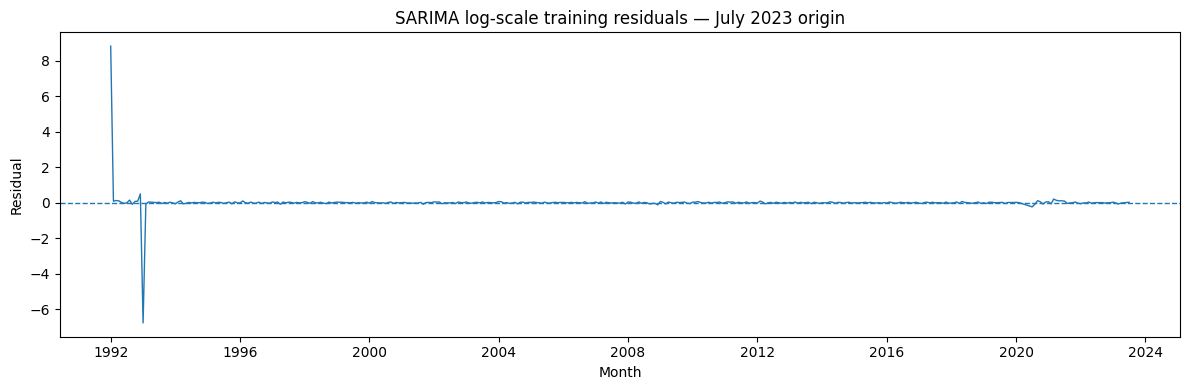

In [11]:
diagnostic_train = y.loc[: "2023-07-01"].copy()

diagnostic_fit, diagnostic_spec = (
    fit_sarima_for_diagnostics(
        diagnostic_train,
        transform="log",
    )
)

print("Selected SARIMA specification:")
print(diagnostic_spec)

residuals = pd.Series(
    np.asarray(diagnostic_fit.resid, dtype=float),
    index=diagnostic_train.index,
    name="Log-scale residual",
).dropna()

ljung_box = acorr_ljungbox(
    residuals,
    lags=[12, 24],
    return_df=True,
)

print("\nLjung-Box residual test:")
display(ljung_box)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    residuals.index,
    residuals.values,
    linewidth=1,
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title(
    "SARIMA log-scale training residuals — July 2023 origin"
)
ax.set_xlabel("Month")
ax.set_ylabel("Residual")

plt.tight_layout()
plt.show()

In [12]:
candidate_summary = (
    model_summary.loc[
        model_summary["Model"].isin(candidate_forecasters)
    ]
    .sort_values(
        ["Pooled_RelMAE_vs_SN", "Complexity_Rank"],
        ascending=[True, True],
    )
    .reset_index(drop=True)
)

finalists = candidate_summary.head(2)

print("Candidate ranking:")
display(
    candidate_summary[
        [
            "Model",
            "Pooled_RelMAE_vs_SN",
            "Pooled_RelMAE_vs_Drift",
            "Folds_Beating_SN",
            "Mean_Bias",
            "Mean_December_Abs_Pct_Error",
        ]
    ].round(3)
)

print("\nSelected finalists:")
display(finalists.round(3))

Candidate ranking:


,Model,Pooled_RelMAE_vs_SN,Pooled_RelMAE_vs_Drift,Folds_Beating_SN,Mean_Bias,Mean_December_Abs_Pct_Error
0,SARIMA seasonal (log),1.029,1.101,4,227.610,2.348
1,SARIMA seasonal (raw),1.064,1.139,4,69.227,3.104
2,ETS (AICc-selected),1.079,1.155,3,-16.684,2.510
3,"Prophet multiplicative, cps=0.01",1.314,1.406,1,-83.812,5.073
4,"Prophet multiplicative, cps=0.2",1.431,1.531,2,-188.062,4.952
5,SARIMA month-dummy D=0 (log),1.487,1.591,0,480.171,9.537
6,"Prophet multiplicative, cps=0.05",1.520,1.627,0,-31.733,5.584
7,"Prophet additive, cps=0.01",1.826,1.955,0,77.390,5.762
8,"Prophet additive, cps=0.2",1.927,2.062,0,-138.788,6.310
9,"Prophet additive, cps=0.05",2.004,2.145,0,34.005,5.848



Selected finalists:


,Model,Pooled_RelMAE_vs_SN,Pooled_RelMAE_vs_Drift,Folds_Beating_SN,Mean_Bias,Mean_December_Abs_Pct_Error,Complexity_Rank
0,SARIMA seasonal (log),1.029,1.101,4,227.610,2.348,3
1,SARIMA seasonal (raw),1.064,1.139,4,69.227,3.104,2


In [13]:
winner = candidate_summary.iloc[0]
winner_name = winner["Model"]

winner_folds = fold_metrics.loc[
    fold_metrics["Model"] == winner_name
]

worst_fold = winner_folds.sort_values(
    "RelMAE_vs_SN",
    ascending=False,
).iloc[0]

worst_month = (
    calendar_month_errors.loc[
        calendar_month_errors["Model"] == winner_name
    ]
    .sort_values("MAE", ascending=False)
    .iloc[0]
)

passes_bar = (
    winner["Pooled_RelMAE_vs_SN"] <= 0.90
    and winner["Folds_Beating_SN"] >= 4
)

print(
    f"Winner: {winner_name}\n"
    f"Pooled RelMAE vs seasonal naive: "
    f"{winner['Pooled_RelMAE_vs_SN']:.3f}\n"
    f"Pooled RelMAE vs selected drift: "
    f"{winner['Pooled_RelMAE_vs_Drift']:.3f}\n"
    f"Validation folds beating seasonal naive: "
    f"{int(winner['Folds_Beating_SN'])}/6\n"
    f"Meets pre-declared success bar: {passes_bar}\n"
    f"Worst fold: {worst_fold['Origin']} "
    f"(RelMAE={worst_fold['RelMAE_vs_SN']:.3f})\n"
    f"Worst calendar month by MAE: "
    f"{worst_month['Calendar_Month']} "
    f"(MAE=${worst_month['MAE']:.1f}M)\n"
    f"Mean signed bias: ${winner['Mean_Bias']:.1f}M\n"
    f"Mean absolute December % error: "
    f"{winner['Mean_December_Abs_Pct_Error']:.2f}%"
)

Winner: SARIMA seasonal (log)
Pooled RelMAE vs seasonal naive: 1.029
Pooled RelMAE vs selected drift: 1.101
Validation folds beating seasonal naive: 4/6
Meets pre-declared success bar: False
Worst fold: 2018-07 (RelMAE=1.630)
Worst calendar month by MAE: March (MAE=$871.9M)
Mean signed bias: $227.6M
Mean absolute December % error: 2.35%


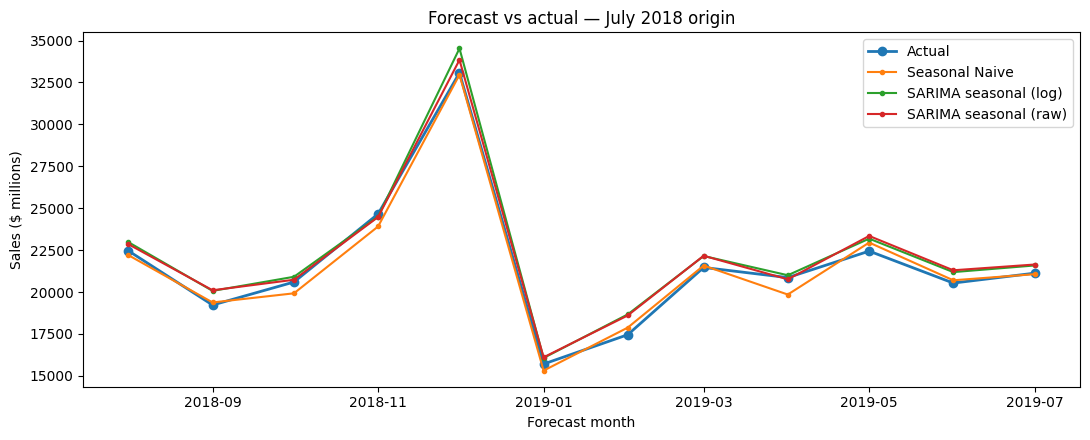

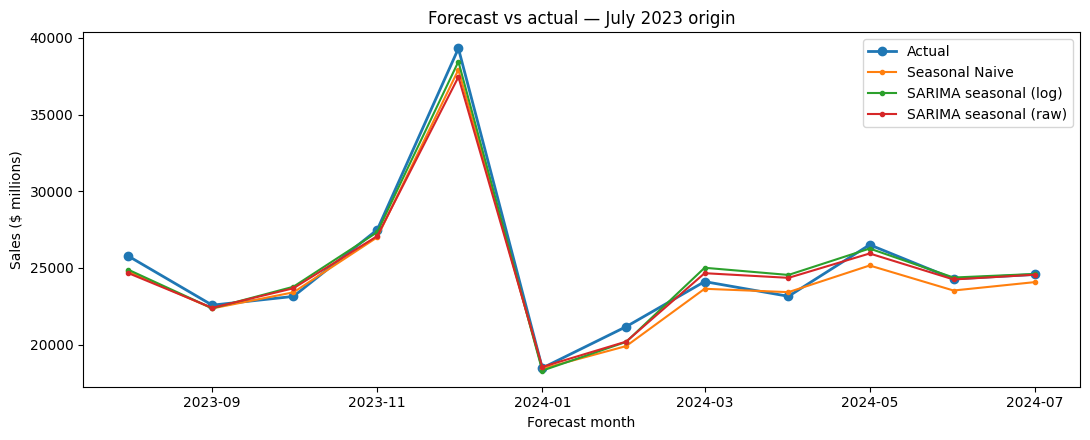

In [14]:
plot_models = [
    "Seasonal Naive",
    *finalists["Model"].tolist(),
]

for origin in ("2018-07", "2023-07"):
    subset = predictions.loc[
        (predictions["Origin"] == origin)
        & predictions["Model"].isin(plot_models)
    ].copy()

    actual_line = (
        subset[["Date", "Actual"]]
        .drop_duplicates("Date")
        .sort_values("Date")
    )

    fig, ax = plt.subplots(figsize=(11, 4.5))

    ax.plot(
        actual_line["Date"],
        actual_line["Actual"],
        marker="o",
        label="Actual",
        linewidth=2,
    )

    for model_name in plot_models:
        model_line = (
            subset.loc[subset["Model"] == model_name]
            .sort_values("Date")
        )

        if not model_line.empty:
            ax.plot(
                model_line["Date"],
                model_line["Forecast"],
                marker=".",
                label=model_name,
            )

    ax.set_title(
        f"Forecast vs actual — July {origin[:4]} origin"
    )
    ax.set_xlabel("Forecast month")
    ax.set_ylabel("Sales ($ millions)")
    ax.legend()
    plt.tight_layout()
    plt.show()

In [15]:
stress_forecasters = {
    "Seasonal Naive": seasonal_naive_forecast,
    drift_name: baseline_forecasters[drift_name],
}

for model_name in finalists["Model"]:
    stress_forecasters[model_name] = candidate_forecasters[model_name]


stress_results = []

for model_name, forecast_fn in stress_forecasters.items():
    result = evaluate(
        forecast_fn,
        y,
        origins=STRESS_ORIGINS,
        mask=False,
    )

    result["Model"] = model_name
    stress_results.append(result)

stress_table = pd.concat(
    stress_results,
    ignore_index=True,
)

display(
    stress_table[
        [
            "Model",
            "Origin",
            "MAE",
            "RMSE",
            "Bias",
            "RelMAE_vs_SN",
            "December_Abs_Pct_Error",
        ]
    ].round(3)
)

,Model,Origin,MAE,RMSE,Bias,RelMAE_vs_SN,December_Abs_Pct_Error
0,Seasonal Naive,2020-07,7039.750,9157.309,-3594.583,1.000,12.286
1,Seasonal Naive,2021-07,3269.167,4077.560,-3146.667,1.000,18.845
2,Drift: trailing-12-month mean YoY,2020-07,7235.858,9151.646,-3189.279,1.028,14.874
3,Drift: trailing-12-month mean YoY,2021-07,3269.167,4077.560,-3146.667,1.000,18.845
4,SARIMA seasonal (log),2020-07,3058.039,3936.098,-2375.713,0.434,2.751
5,SARIMA seasonal (log),2021-07,2149.735,2278.487,2149.735,0.658,7.542
6,SARIMA seasonal (raw),2020-07,3221.355,4076.058,-2076.691,0.458,3.804
7,SARIMA seasonal (raw),2021-07,2192.457,2468.051,2083.315,0.671,1.146
